In [16]:
import numpy as np
import os
import json
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import KFold, cross_val_score

In [17]:
EXP_NAME = "cam3_revB_batch1_10_margin_15_yolov8n_wb_alif_clahe_box_01_dfl_01_2nd"

INPUT_FODLER = f"wb_alif_clahe_collected_outputs_{EXP_NAME}"

buf_fp32_scores = np.load(os.path.join(INPUT_FODLER, 'fp32_scores.npy'))
buf_fp32_boxes = np.load(os.path.join(INPUT_FODLER, 'fp32_boxes.npy'))
buf_uint8_scores = np.load(os.path.join(INPUT_FODLER, 'uint8_scores.npy'))
buf_uint8_boxes = np.load(os.path.join(INPUT_FODLER, 'uint8_boxes.npy'))

buf_fp32_scores.shape, buf_fp32_boxes.shape, buf_uint8_scores.shape, buf_uint8_boxes.shape

((10910, 1), (10910, 6), (10910, 1), (10910, 6))

(0.09314478, 0.05142124, 0.08750245, 0.70702934)

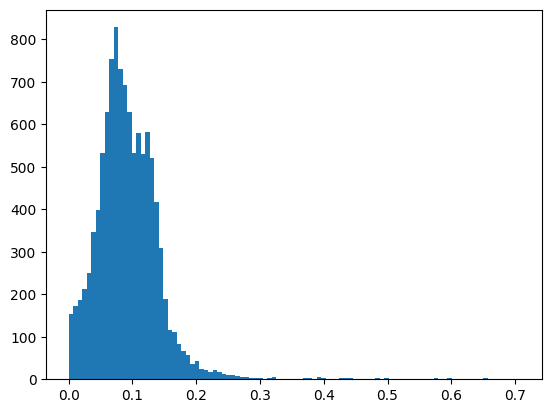

In [18]:
scores_dif = np.abs(buf_fp32_scores - buf_uint8_scores).flatten()
plt.hist(scores_dif, bins=100);
scores_dif.mean(), scores_dif.std(), np.median(scores_dif), scores_dif.max()

Coord dif mean: [6.6477857 5.9936295 8.925705  9.707228  4.6788673 4.7525697]
Coord dif std: [4.635752  4.6763234 6.888269  6.9782615 3.0574484 3.079952 ]
Coord dif median: [5.936983  5.1882296 7.4510326 8.416615  4.2242165 4.255604 ]
Coord dif max: [17.953033 28.562378 32.409534 34.517204 14.24968  15.620277]


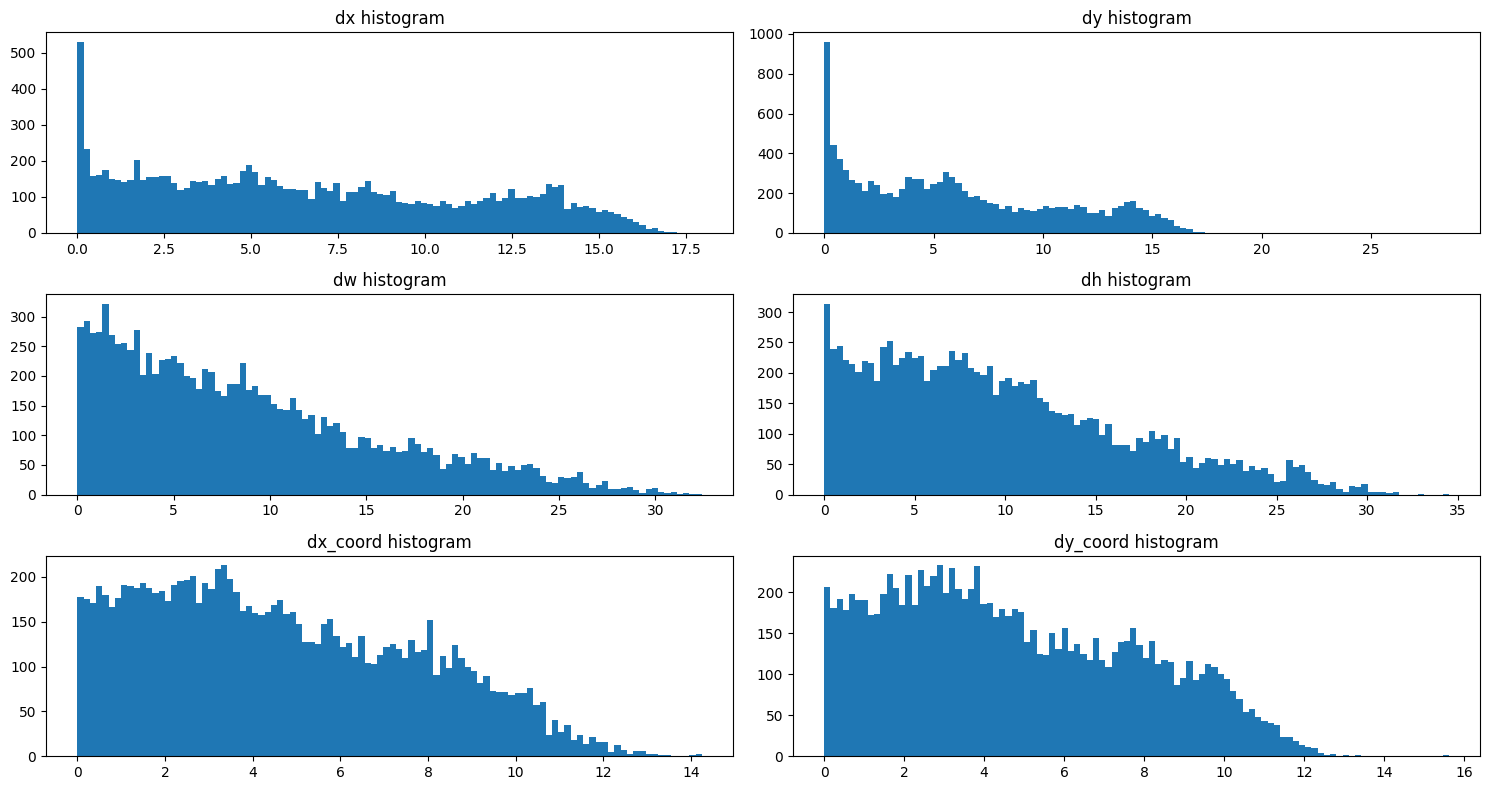

In [19]:
coord_dif = np.abs(buf_fp32_boxes - buf_uint8_boxes)
print("Coord dif mean:", coord_dif.mean(axis=0))
print("Coord dif std:", coord_dif.std(axis=0))
print("Coord dif median:", np.median(coord_dif, axis=0))
print("Coord dif max:", coord_dif.max(axis=0))

plt.figure(figsize=(15, 8))
plt.subplot(3, 2, 1)
plt.hist(coord_dif[:, 0].flatten(), bins=100)
plt.title('dx histogram')
plt.subplot(3, 2, 2)
plt.hist(coord_dif[:, 1].flatten(), bins=100)
plt.title('dy histogram')
plt.subplot(3, 2, 3)
plt.hist(coord_dif[:, 2].flatten(), bins=100)
plt.title('dw histogram')
plt.subplot(3, 2, 4)
plt.hist(coord_dif[:, 3].flatten(), bins=100)
plt.title('dh histogram')
plt.subplot(3, 2, 5)
plt.hist(coord_dif[:, 4].flatten(), bins=100)
plt.title('dx_coord histogram')
plt.subplot(3, 2, 6)
plt.hist(coord_dif[:, 5].flatten(), bins=100)
plt.title('dy_coord histogram')

plt.tight_layout()


In [20]:
# Train linear regression models for all 6 box coordinates
coord_names = ['dx', 'dy', 'dw', 'dh', 'dx_coord', 'dy_coord']
models = []

params = {}

# First: Train models on full dataset
for i in range(6):
    # X = buf_uint8_boxes[:, i].reshape(-1, 1)
    X = buf_uint8_boxes
    y = buf_fp32_boxes[:, i]
    
    # model = LinearRegression(fit_intercept=True)
    model = RidgeCV(fit_intercept=True, alphas=np.logspace(-2, 1, 50))
    model.fit(X, y)
    models.append(model)

    print(f"{coord_names[i]}:")
    print(f"  Coef: {model.coef_}, Intercept: {model.intercept_:.6f}, Alpha: {model.alpha_ if hasattr(model, 'alpha_') else 'N/A'}")
    params[coord_names[i]] = {
        'coef': [float(i) for i in model.coef_],
        'intercept': float(model.intercept_),
        'alpha': float(model.alpha_) if hasattr(model, 'alpha_') else None
    }

print("\n" + "="*50)
print("Model training completed\n")

# MSE comparison: FP32 vs UINT8 (without regression)
print("\n" + "="*50)
print("MSE: FP32 vs UINT8 (direct conversion)\n")
mse_uint8 = mean_squared_error(buf_fp32_boxes, buf_uint8_boxes, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_uint8[i]:.4f}")
print(f"Overall MSE: {mse_uint8.mean():.4f}")

# MSE comparison: FP32 vs Regression predictions (UINT8 as input)
print("\n" + "="*50)
print("MSE: FP32 vs Regression predictions (UINT8 input)\n")
predictions = np.column_stack([models[i].predict(buf_uint8_boxes) for i in range(6)])
mse_regression = mean_squared_error(buf_fp32_boxes, predictions, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_regression[i]:.4f}")
print(f"Overall MSE: {mse_regression.mean():.4f}")

# Improvement comparison
print("\n" + "="*50)
print("MSE Improvement (UINT8 -> Regression)\n")
for i, name in enumerate(coord_names):
    improvement = ((mse_uint8[i] - mse_regression[i]) / mse_uint8[i]) * 100
    print(f"{name}: {improvement:.2f}%")
print(f"Overall: {((mse_uint8.mean() - mse_regression.mean()) / mse_uint8.mean()) * 100:.2f}%")

file_name = f'ridge_regression_params_{EXP_NAME}.json'
with open(file_name, 'w') as f:
    json.dump(params, f, indent=4)
print(f"\nRegression parameters saved to '{file_name}'")

dx:
  Coef: [ 0.8355445  -0.01343554  0.10593891 -0.02023983  0.19638233  0.00889322], Intercept: -16.172632, Alpha: 10.0
dy:
  Coef: [ 1.16502570e-02  8.54173426e-01 -1.30888732e-02  1.36429821e-01
 -6.67431837e-04  1.58191347e-01], Intercept: -14.147383, Alpha: 10.0
dw:
  Coef: [ 0.02482626  0.00997204  0.64042373  0.05424832 -0.0338354  -0.00965786], Intercept: 21.716670, Alpha: 10.0
dh:
  Coef: [ 0.02407024 -0.00242152  0.06146331  0.56025405 -0.04898121  0.00737235], Intercept: 25.106772, Alpha: 10.0
dx_coord:
  Coef: [ 0.1740674  -0.00762337  0.08790407 -0.02477413  0.78699042  0.01164014], Intercept: 7.286546, Alpha: 10.0
dy_coord:
  Coef: [ 0.00534353  0.19167734  0.00354131  0.10852587 -0.00337973  0.7737722 ], Intercept: 3.472033, Alpha: 10.0

Model training completed


MSE: FP32 vs UINT8 (direct conversion)

dx: 65.6830
dy: 57.7917
dw: 127.1167
dh: 142.9265
dx_coord: 31.2398
dy_coord: 32.0729
Overall MSE: 76.1384

MSE: FP32 vs Regression predictions (UINT8 input)

dx: 47.231